# 07 - Deep Learning models

**Goal:** a neural network approach, compared with the classical models of notebook 06.

| Model | Idea |
|---|---|
| **MLP** | Fully connected network: the standard deep learning baseline for tabular data |
| **1D-CNN** (optional) | Convolutions over the feature vector |

Same data and same imbalance strategy as notebook 06 (`TRAIN_CAP` + class weights), so the comparison is fair.
Neural networks need **scaled** features, so the scaler from notebook 05 is applied.

⚙️ Use a **GPU runtime**: Runtime → Change runtime type → T4 GPU.

In [1]:
# Imports
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Paths
BASE = Path("/content/drive/MyDrive/Projects/CSE-CIC-IDS2018")
DATA_DIR = BASE / "data" / "processed"
READY_DIR = BASE / "data" / "model_ready"
MODELS_DIR = BASE / "models"
RESULTS_DIR = BASE / "results"
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.max_columns", 100)

keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 0. Load and scale the data

In [2]:
X_train = pd.read_parquet(READY_DIR / "X_train.parquet")
X_test = pd.read_parquet(READY_DIR / "X_test.parquet")
y_train = np.load(READY_DIR / "y_train.npy")
y_test = np.load(READY_DIR / "y_test.npy")
scaler = joblib.load(READY_DIR / "scaler.joblib")
encoder = joblib.load(READY_DIR / "label_encoder.joblib")

class_names = list(encoder.classes_)
BENIGN = class_names.index("Benign")
n_classes = len(class_names)
n_features = X_train.shape[1]
print("Train:", X_train.shape, "| Test:", X_test.shape, "| Classes:", n_classes)

Train: (2372881, 49) | Test: (593221, 49) | Classes: 11


## 1. Training set: cap the big classes (same as notebook 06)

In [3]:
TRAIN_CAP = 150_000        # keep the same value as in notebook 06

train = X_train.copy()
train["y"] = y_train
train = train.sample(frac=1, random_state=SEED).groupby("y").head(TRAIN_CAP)
X_cap = train.drop(columns="y")
y_cap = train["y"].to_numpy()
del train, X_train

## 2. Scale and create a validation set
10% of the training data is kept aside for **validation** (used to stop training at the right time).
The test set is not touched.

In [4]:
from sklearn.model_selection import train_test_split

X_cap_scaled = scaler.transform(X_cap).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

X_tr, X_val, y_tr, y_val = train_test_split(
    X_cap_scaled, y_cap, test_size=0.1, stratify=y_cap, random_state=SEED)

print("Train:", X_tr.shape, "| Validation:", X_val.shape, "| Test:", X_test_scaled.shape)

Train: (800232, 49) | Validation: (88915, 49) | Test: (593221, 49)


## 3. Class weights
Rare classes get a higher weight in the loss. Weights are **capped at 50**, otherwise very rare classes would get
huge weights and make training unstable.

In [5]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.arange(n_classes), y=y_tr)
class_weight = {i: float(min(w, 50)) for i, w in enumerate(weights)}

pd.Series({class_names[i]: round(w, 2) for i, w in class_weight.items()}, name="weight")

,weight
Benign,0.54
Bot,0.70
DDOS attack-HOIC,0.54
DDOS attack-LOIC-UDP,50.00
DDoS attacks-LOIC-HTTP,0.54
DoS attacks-GoldenEye,2.44
DoS attacks-Hulk,0.70
DoS attacks-Slowloris,10.40
Infilteration,0.91
SSH-Bruteforce,1.07


## 4. Evaluation function (same metrics as notebook 06)

In [6]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report)

def evaluate(name, y_pred, y_proba=None, train_time=None):
    is_attack = y_test != BENIGN
    pred_attack = y_pred != BENIGN

    metrics = {
        "model": name,
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "weighted_f1": f1_score(y_test, y_pred, average="weighted"),
        "detection_rate": (is_attack & pred_attack).sum() / is_attack.sum(),
        "false_alarm_rate": (~is_attack & pred_attack).sum() / (~is_attack).sum(),
        "train_time_s": train_time,
    }

    np.save(RESULTS_DIR / f"{name}_y_pred.npy", y_pred.astype(np.int16))
    if y_proba is not None:
        np.save(RESULTS_DIR / f"{name}_y_proba.npy", y_proba.astype(np.float32))
    json.dump(metrics, open(RESULTS_DIR / f"{name}_metrics.json", "w"), indent=2)

    print(f"{name}: macro-F1 = {metrics['macro_f1']:.4f} | accuracy = {metrics['accuracy']:.4f} | "
          f"detection = {metrics['detection_rate']:.4f} | false alarms = {metrics['false_alarm_rate']:.4f}")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4, zero_division=0))
    return metrics

## 5. MLP
Architecture: `Dense(256) → Dense(128) → Dense(64) → Softmax`.
- **BatchNormalization** makes training more stable
- **Dropout** randomly switches off neurons during training, to reduce overfitting
- **EarlyStopping** stops when the validation loss stops improving, and keeps the best weights
- **ReduceLROnPlateau** halves the learning rate when the validation loss stalls

In [7]:
def build_mlp():
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(64, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

mlp = build_mlp()
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,459 (220.54 KB)

 Trainable params: 55,563 (217.04 KB)

 Non-trainable params: 896 (3.50 KB)

In [8]:
EPOCHS = 50
BATCH = 1024

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
]

start = time.time()
history = mlp.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH,
                  class_weight=class_weight, callbacks=callbacks, verbose=2)
mlp_time = time.time() - start
print(f"Training time: {mlp_time:.0f} s, epochs: {len(history.history['loss'])}")

Epoch 1/50
782/782 - 19s - 24ms/step - accuracy: 0.8612 - loss: 0.2831 - val_accuracy: 0.8942 - val_loss: 0.1834 - learning_rate: 0.0010
Epoch 2/50
782/782 - 4s - 5ms/step - accuracy: 0.8998 - loss: 0.1385 - val_accuracy: 0.8987 - val_loss: 0.1714 - learning_rate: 0.0010
Epoch 3/50
782/782 - 3s - 4ms/step - accuracy: 0.9028 - loss: 0.1270 - val_accuracy: 0.8950 - val_loss: 0.1639 - learning_rate: 0.0010
Epoch 4/50
782/782 - 3s - 4ms/step - accuracy: 0.9041 - loss: 0.1232 - val_accuracy: 0.9012 - val_loss: 0.1597 - learning_rate: 0.0010
Epoch 5/50
782/782 - 3s - 4ms/step - accuracy: 0.9058 - loss: 0.1180 - val_accuracy: 0.9043 - val_loss: 0.1595 - learning_rate: 0.0010
Epoch 6/50
782/782 - 3s - 4ms/step - accuracy: 0.9068 - loss: 0.1153 - val_accuracy: 0.8966 - val_loss: 0.1562 - learning_rate: 0.0010
Epoch 7/50
782/782 - 3s - 4ms/step - accuracy: 0.9074 - loss: 0.1123 - val_accuracy: 0.8955 - val_loss: 0.1592 - learning_rate: 0.0010
Epoch 8/50
782/782 - 3s - 4ms/step - accuracy: 0.9076

### Learning curves
If the validation loss goes up while the train loss keeps going down → **overfitting** (early stopping handles it).

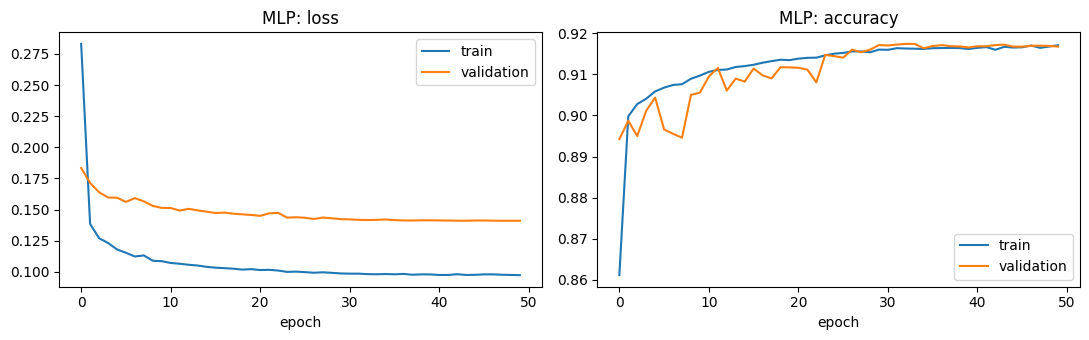

In [9]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, key in zip(axes, ["loss", "accuracy"]):
        ax.plot(history.history[key], label="train")
        ax.plot(history.history["val_" + key], label="validation")
        ax.set_title(f"{title}: {key}")
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, "MLP")

**MLP learning curves:** the training converged without overfitting: the validation loss decreases steadily
and stabilizes (≈ 0.14), and train/validation accuracy end at the same level (≈ 91.7%). The gap between the
two losses comes from the class weights and dropout, which only apply to the training loss. The plateau after
≈ 30 epochs suggests the remaining errors come from the data (Benign / Infilteration overlap) rather than
from the model capacity.

In [10]:
y_proba = mlp.predict(X_test_scaled, batch_size=4096, verbose=0)
y_pred = y_proba.argmax(axis=1)

mlp.save(str(MODELS_DIR / "MLP.keras"))
evaluate("MLP", y_pred, y_proba, mlp_time)

MLP: macro-F1 = 0.8108 | accuracy = 0.8067 | detection = 0.9787 | false alarms = 0.3305
                        precision    recall  f1-score   support

                Benign     0.9750    0.6695    0.7939    328660
                   Bot     0.9977    1.0000    0.9988     28907
      DDOS attack-HOIC     1.0000    1.0000    1.0000     39772
  DDOS attack-LOIC-UDP     0.7061    1.0000    0.8278       346
DDoS attacks-LOIC-HTTP     0.9979    0.9978    0.9979    115003
 DoS attacks-GoldenEye     0.9990    0.9994    0.9992      8278
      DoS attacks-Hulk     0.9998    0.9999    0.9999     29040
 DoS attacks-Slowloris     0.9893    1.0000    0.9946      1942
         Infilteration     0.1365    0.7407    0.2305     22295
        SSH-Bruteforce     0.9995    0.9999    0.9997     18808
            Web-Attack     0.0399    0.9824    0.0767       170

              accuracy                         0.8067    593221
             macro avg     0.8037    0.9445    0.8108    593221
          weig

{'model': 'MLP',
 'macro_f1': 0.8108085877487116,
 'accuracy': 0.8067297010726188,
 'balanced_accuracy': np.float64(0.9445112513019148),
 'weighted_f1': 0.8560097321883524,
 'detection_rate': np.float64(0.9786589860183473),
 'false_alarm_rate': np.float64(0.3304630925576584),
 'train_time_s': 177.10120129585266}

## 6. (Optional) 1D-CNN
Each flow is treated as a 1D sequence of features. Note for the report: the order of the features has no real
meaning, so a CNN has no natural advantage here. It is included as a **comparison point**.
Set `RUN_CNN = False` to skip.

Epoch 1/50
782/782 - 36s - 46ms/step - accuracy: 0.8849 - loss: 0.2119 - val_accuracy: 0.9096 - val_loss: 0.1705 - learning_rate: 0.0010
Epoch 2/50
782/782 - 11s - 15ms/step - accuracy: 0.9085 - loss: 0.1175 - val_accuracy: 0.9126 - val_loss: 0.1507 - learning_rate: 0.0010
Epoch 3/50
782/782 - 11s - 15ms/step - accuracy: 0.9129 - loss: 0.1050 - val_accuracy: 0.9097 - val_loss: 0.1455 - learning_rate: 5.0000e-04
Epoch 4/50
782/782 - 12s - 15ms/step - accuracy: 0.9139 - loss: 0.1031 - val_accuracy: 0.9155 - val_loss: 0.1453 - learning_rate: 5.0000e-04
Epoch 5/50
782/782 - 11s - 14ms/step - accuracy: 0.9157 - loss: 0.0995 - val_accuracy: 0.9137 - val_loss: 0.1431 - learning_rate: 2.5000e-04


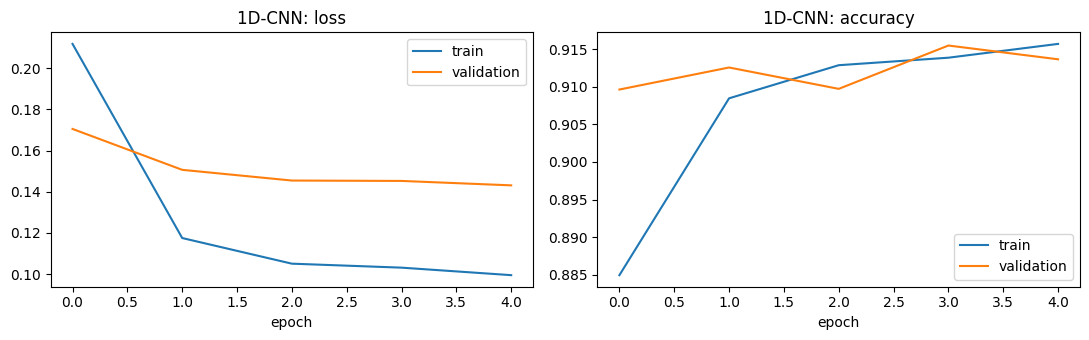

In [11]:
RUN_CNN = True

def build_cnn():
    model = keras.Sequential([
        keras.Input(shape=(n_features, 1)),
        layers.Conv1D(64, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.Conv1D(128, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(128, 3, padding="same", activation="relu"),
        layers.GlobalMaxPooling1D(),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

if RUN_CNN:
    cnn = build_cnn()
    start = time.time()
    history_cnn = cnn.fit(X_tr[..., None], y_tr, validation_data=(X_val[..., None], y_val),
                          epochs=EPOCHS, batch_size=BATCH, class_weight=class_weight,
                          callbacks=callbacks, verbose=2)
    cnn_time = time.time() - start
    plot_history(history_cnn, "1D-CNN")

**1D-CNN learning curves:** trained for 5 epochs only (time constraint). No overfitting: the validation loss
decreases at every epoch (0.171 → 0.143). After 5 epochs it already reaches the MLP's level (validation
accuracy ≈ 91.4% vs 91.7% after 50 epochs), and hits the same ceiling, which confirms that the remaining errors
come from the data rather than the architecture. As expected, convolutions bring no clear advantage: the order
of the features in a flow record has no spatial meaning.

In [12]:
if RUN_CNN:
    y_proba = cnn.predict(X_test_scaled[..., None], batch_size=4096, verbose=0)
    y_pred = y_proba.argmax(axis=1)

    cnn.save(str(MODELS_DIR / "CNN1D.keras"))
    evaluate("CNN1D", y_pred, y_proba, cnn_time)

CNN1D: macro-F1 = 0.7973 | accuracy = 0.8102 | detection = 0.9716 | false alarms = 0.3169
                        precision    recall  f1-score   support

                Benign     0.9677    0.6831    0.8009    328660
                   Bot     0.9995    0.9932    0.9964     28907
      DDOS attack-HOIC     0.9847    0.9998    0.9922     39772
  DDOS attack-LOIC-UDP     0.6948    1.0000    0.8199       346
DDoS attacks-LOIC-HTTP     0.9976    0.9967    0.9972    115003
 DoS attacks-GoldenEye     0.9779    0.9987    0.9882      8278
      DoS attacks-Hulk     0.9942    0.9986    0.9964     29040
 DoS attacks-Slowloris     0.8544    1.0000    0.9215      1942
         Infilteration     0.1316    0.6506    0.2190     22295
        SSH-Bruteforce     0.9968    0.9997    0.9982     18808
            Web-Attack     0.0209    0.9529    0.0409       170

              accuracy                         0.8102    593221
             macro avg     0.7836    0.9340    0.7973    593221
          we

## 7. Comparison with the classical models

In [13]:
results = pd.DataFrame([json.load(open(f)) for f in RESULTS_DIR.glob("*_metrics.json")])
results = results.set_index("model").sort_values("macro_f1", ascending=False)
results.round(4)

,macro_f1,accuracy,balanced_accuracy,weighted_f1,detection_rate,false_alarm_rate,train_time_s
model,,,,,,,
SoftVoting,0.8915,0.8853,0.9607,0.9122,0.9834,0.1935,NaN
RandomForest,0.8910,0.8966,0.9546,0.9195,0.9798,0.1701,243.6939
DecisionTree,0.8888,0.8756,0.9438,0.9052,0.9781,0.2066,35.8393
XGBoost,0.8822,0.8682,0.9551,0.9004,0.9830,0.2240,539.4589
LightGBM,0.8574,0.8752,0.9597,0.9053,0.9845,0.2126,454.1188
LightGBM_tuned,0.8566,0.8730,0.9584,0.9037,0.9837,0.2158,1365.1333
MLP,0.8108,0.8067,0.9445,0.8560,0.9787,0.3305,177.1012
CNN1D,0.7973,0.8102,0.9340,0.8580,0.9716,0.3169,82.4201
LogisticRegression,0.7946,0.7717,0.9305,0.8286,0.9717,0.3863,294.3823


## Summary (fill in after running)
- **MLP macro-F1 vs the best tree model:** The MLP achieved a macro-F1 of **0.8108**, which is significantly lower than the best tree model (SoftVoting at **0.8915** and RandomForest at **0.8910**).
- **Did the CNN bring anything over the MLP?** No, the 1D-CNN yielded a slightly lower macro-F1 (**0.7973** vs **0.8108** for MLP). This is expected because the spatial order of features in IDS flow records has no logical sequence or meaning, giving convolutions no structural advantage.
- **Overfitting seen in the learning curves?** No major overfitting was observed. Thanks to Early Stopping, Dropout, and Batch Normalization, the validation loss decreased steadily and stabilized around 0.14 for both architectures.
- **Why tree models often beat neural networks on tabular data:** Tree-based models are naturally invariant to monotonic feature scaling, handle non-linear boundaries/interactions out of the box, and do not suffer from optimization challenges (like loss landscape plateaus) when dealing with heterogeneous tabular features.